# Board Game Recommender System

**Data:** BoardGameGeek (BGG) ratings, two snapshots of the same site: **January 2022** (19.0M ratings) and **February 2025** (26.2M ratings), plus detailed game metadata (Kaggle `jvanelteren/boardgamegeek-reviews`).

**Goal:** recommend board games to users from their past ratings with collaborative filtering (Surprise), and check what a good recommender really needs.

**Experimental design in one sentence:** models learn from what was known in **January 2022** and are tested twice, on a random 20% of those 2022 ratings (the classic split) and on the ratings the same users actually gave **later, by 2025** (the future).

| Section | Assignment task |
|---|---|
| 1 | Data preprocessing: loading, cleaning, the two snapshots, the experimental frame, normalisation |
| 2 | Exploratory data analysis |
| 3 | Building the recommender: the models, tuning, training |
| 4 | Evaluation: RMSE/MAE, precision/recall/NDCG over the full catalogue, random split vs future |
| 5 | Making recommendations: example users, one game you love, coverage, novelty, diversity |
| 6 | Visualisation and interpretation |
| 7 | Conclusions, then an appendix on robustness |

## Summary

| Question | Answer |
|---|---|
| Does collaborative filtering beat the baselines at **predicting ratings**? | **Yes, modestly.** Tuned SVD: RMSE 1.171 (+3.7% over `BaselineOnly`); averaged with item-KNN: 1.167 (+4.1%). Most of what is predictable is *how generous a user is* and *how good a game is*. |
| Does **better rating prediction** give **better recommendation lists**? | **No.** Every rating model loses to "the most popular games" on top-10 lists (SVD++ P@10 0.031 vs 0.077). The list models win: **EASE P@10 0.145**, and **69% of users** find a game they love in their top 10, against 47% with popularity. |
| Does a **random split** tell the truth about the future? | **Not fully.** On what users rated *after* January 2022 every model gets worse, popularity collapses (P@10 0.090 → 0.039 on the same users), and the co-rating model's large lead over SVD disappears. EASE stays clearly best (+0.025 over SVD, 95% CI [+0.022, +0.027]). 55% of what users rated next was not even in the 2022 catalogue. |
| Did the model learn anything **interpretable**? | **Yes.** Without seeing any game metadata, the SVD factors separate heavy hobby games from mass-market games (r = −0.69 with complexity) and thematic dice-and-fantasy games from abstract classics. EASE's recommendations follow each user's taste in complexity (r = 0.87). |

All code lives in the `bgg_recsys` package next to this notebook; each cell below states a decision or shows a result.

In [1]:
QUICK = False   # True: a small frame for a smoke run (same code, a few minutes)

In [2]:
import numpy as np
import pandas as pd

from bgg_recsys import analysis, data, evaluation, metrics, tuning
from bgg_recsys.config import CONFIG
from bgg_recsys.evaluation import SPLITS
from bgg_recsys.models import (
    Name,
    Tuned,
    best_item_knn,
    list_group,
    list_scorers,
    rating_models,
)
from bgg_recsys.models import catalogue as pick
from bgg_recsys.models.catalogue import verify_rating_scorers
from bgg_recsys.report import figures, style
from bgg_recsys.report.tables import facts, show

cfg = CONFIG.quick() if QUICK else CONFIG
seed, k, liked = cfg.frame.seed, cfg.k, cfg.liked
style.use(cfg.paths.figures)
show(cfg.describe(), "Decisions behind every result")

,decision
,
catalogue,"the 2,000 most-rated games in Jan 2022"
users,"15,000 sampled (seed 42) among users with ≥ 20 ratings on the catalogue"
random test split,20% of their 2022 ratings
future test set,their ratings added between Jan 2022 and Feb 2025
validation split,"10% of the training ratings (SVD epochs, EASE)"
liked / relevant,rating ≥ 8
list length,top 10
item-KNN grid,"k ∈ (20, 40, 80) × similarity ∈ ('msd', 'cosine', 'pearson_baseline'), 3-fold CV"
SVD grid,"factors ∈ (50, 100, 200, 300) × reg ∈ (0.05, 0.1, 0.15, 0.2), lr 0.005, 3-fold CV"


## 1. Data Preprocessing
### 1.1 Loading

- `ratings.parquet` (Feb 2025) and `ratings_2022.parquet` (Jan 2022): one row per (user, game) rating. `scripts/download_data.py` builds them from the Kaggle CSVs and drops the free-text comment column, which we don't use.
- `games_detailed_info2025.csv`: one row per game with BGG metadata (year, complexity "weight", play time, categories, mechanics).

In [3]:
d = data.load(cfg.paths)
show(analysis.snapshot_overview(d), "Snapshots after cleaning", formats={"density": "small share"})
show(d.new.ratings.head(3))
show(d.games[["name", "yearpublished", "averageweight", "playingtime", "categories", "mechanics"]].head(3), formats={"yearpublished": "year"})

,ratings,users,games,density
Jan 2022,18964728.000,412815.000,21839.000,0.210%
Feb 2025,26199934.000,555481.000,27865.000,0.169%


,user,ID,rating
0,sidehacker,13,10.000
1,Varthlokkur,13,10.000
2,dougthonus,13,10.000


,name,yearpublished,averageweight,playingtime,categories,mechanics
ID,,,,,,
13,CATAN,1995,2.288,120.000,"['Economic', 'Negotiation']","['Chaining', 'Dice Rolling', 'Hexagon Grid', 'Income', 'Modular Board', 'Negotiation', 'Network and Route Building', 'Race', 'Random Production', 'Trading', 'Variable Set-up']"
822,Carcassonne,2000,1.889,45.000,"['Medieval', 'Territory Building']","['Area Majority / Influence', 'Enclosure', 'Map Addition', 'Pattern Building', 'Tile Placement']"
30549,Pandemic,2008,2.397,45.000,['Medical'],"['Action Points', 'Cooperative Game', 'Hand Management', 'Point to Point Movement', 'Set Collection', 'Tags', 'Variable Player Powers']"


### 1.2 Cleaning

**Ratings.** BGG allows ratings from 1 to 10, with decimals (e.g. 7.5). We remove rows with a missing username, ratings below 1 (corrupt values) and duplicate (user, game) pairs. Decimals are kept.

**Metadata.** List columns are stored as strings (`"['Dice Rolling', ...]"`) and get parsed. A 0 for year, complexity or play time means "unknown". Negative years are real: ancient games such as Go and Senet are dated BCE.

In [4]:
show(analysis.cleaning_report(d), "Rows removed")
print("corrupt rating values removed from the 2025 file:", d.new.corrupt_values)
show(d.game_fixes, "Metadata fixes")
facts({**analysis.metadata_coverage(d.new.ratings, d.games), **analysis.rating_decimals(d.new.ratings)}, "Ratings (2025)",
      formats={"share of ratings on games without metadata": "small share", "integer": "share", "half point": "share", "other decimals": "share"})

,Jan 2022,Feb 2025
missing username,66,66
rating below 1 (corrupt),13,12
"duplicate (user, game)",0,0


corrupt rating values removed from the 2025 file: [1.4013e-45, 0.0001, 0.001, 0.001, 0.001, 0.1, 0.1, 0.1, 0.5, 0.5, 0.5, 0.5]


,games
yearpublished == 0 -> missing,242
averageweight == 0 -> missing,494
playingtime == 0 -> missing,"1,173"
"yearpublished < 0 (ancient games, kept)",10
duplicate game IDs,0


,value
share of ratings on games without metadata,0.016%
games without metadata,85.000
integer,83.0%
half point,11.5%
other decimals,5.5%


### 1.3 Two snapshots: what happened between January 2022 and February 2025

The dataset has no rating dates, but comparing the two snapshots pair by pair tells us which ratings were **added**, **changed** or **removed** in those three years. The added ratings are what lets us test models on the future (section 1.4).

In [5]:
show(d.diff.summary(), "Changes per (user, game) pair")
show(analysis.new_rating_origins(d), "Who gave the new ratings?", default="share")

,pairs
unchanged,"17,435,790"
re-rated (value changed),"959,995"
new in the later snapshot,"7,804,149"
disappeared,"568,943"


ID,game new since 2022,game rated in 2022
user,,
new user,5.8%,35.2%
user already in 2022,13.8%,45.3%


### 1.4 The experimental frame

Everything that defines the frame comes from the **2022 snapshot only**:
1. **Catalogue:** the 2,000 most-rated games in 2022.
2. **Users:** those with at least 20 ratings on the catalogue, enough history for collaborative filtering; we sample 15,000 of them (fixed seed). Neighbourhood methods in Surprise store a dense similarity matrix, and this size keeps training, tuning and cross-validation to minutes.
3. **Random split:** their 2022 ratings, split 80/20 at random. The 80% trains every model; the 20% is the classic test set.
4. **Future test set:** the ratings the same users gave to catalogue games **between Jan 2022 and Feb 2025**.

Each model is trained once and evaluated on both test sets. The EDA (section 2) uses all 2025 data; the models deliberately hold back the newest three years so they can be tested on them.

In [6]:
choices = [(d.old.ratings.ID.nunique(), 1), (6_000, 20), (4_000, 50), (cfg.frame.n_games, cfg.frame.min_user_ratings)]
show(analysis.core_sizes(d.old.ratings, choices), "Size of the core for different filters (2022 snapshot)",
     formats={"density": "share", "share of all ratings": "share"})
frame = data.load_frame(cfg.frame, cfg.paths)
show(frame.sizes(), "The frame")
facts(frame.check(), "Leakage and consistency checks")

,games kept,min ratings/user,ratings,users,games,density,share of all ratings
0,"top 21,839",1,"18,964,728","412,815","21,839",0.2%,100.0%
1,"top 6,000",20,"15,955,473","162,981","6,000",1.6%,84.1%
2,"top 4,000",50,"12,664,579","85,392","4,000",3.7%,66.8%
3,"top 2,000",20,"13,022,046","151,769","2,000",4.3%,68.7%


,ratings,users,games
train,"1,017,462","15,000","2,000"
random test,"254,366","14,979","2,000"
future test,"164,269","7,518","1,995"


,value
"no (user, game) pair in more than one set",✓
every test user and game has training ratings,✓
min training ratings per game,83
min training ratings per user,10
sampled users who rated catalogue games later,50%


### 1.5 Normalisation

Users use the scale differently: some rate everything 8+, others are harsh. Collaborative filtering has to separate *taste* from *rating habit*. We don't rescale the stored ratings; the models normalise internally, and section 4.1 measures how much that matters:
- `KNNWithMeans` works on mean-centred ratings (r<sub>ui</sub> − mean<sub>u</sub>), `KNNWithZScore` also divides by the user's spread;
- `BaselineOnly`, `KNNBaseline` and `SVD` learn a user bias b<sub>u</sub> and an item bias b<sub>i</sub> on top of the global mean μ.

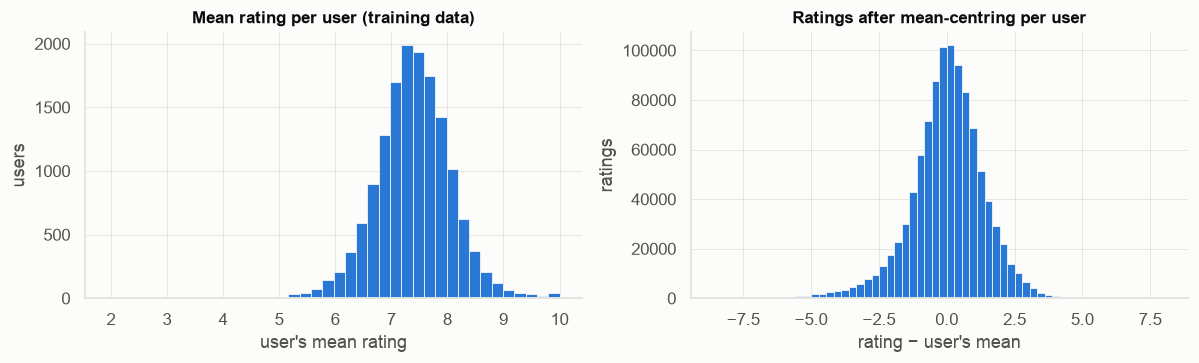

In [7]:
figures.normalisation(frame.train)

## 2. Exploratory Data Analysis
All 26.2M ratings of the 2025 snapshot.
### 2.1 Rating distribution

,value
mean,7.13
median,7.00
std,1.59
share 6–8,67.0%
share ≥ 8,39.0%


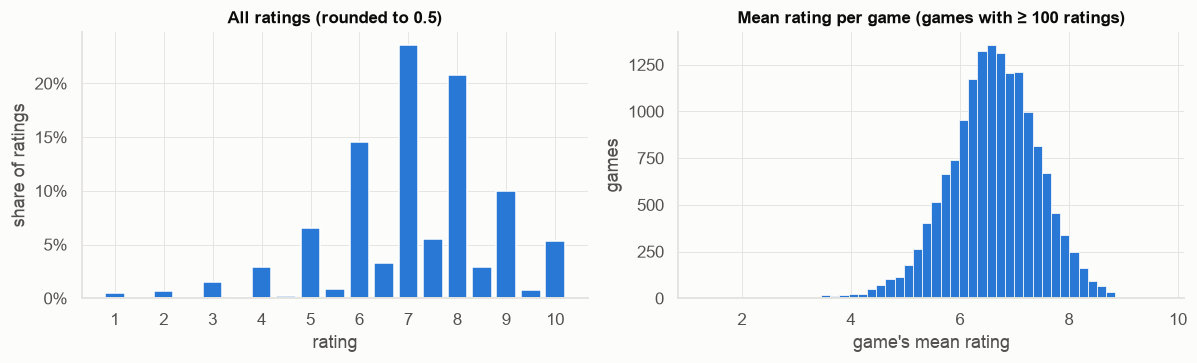

In [8]:
games = analysis.game_stats(d)
figures.rating_distribution(d.new.ratings, games)
facts(analysis.rating_summary(d.new.ratings, liked), formats={"share 6–8": "share", f"share ≥ {liked:g}": "share", "mean": "rating", "median": "rating", "std": "rating"})

### 2.2 User behaviour: activity and generosity

,value
median ratings per user,11
90th percentile,117
share who rated a single game,20.6%
"users with ≥ 20 ratings, all identical",435.000


,n,mean,std
user,,,
oldgoat3769967,"16,792",6.05,1.42
Tolkana,"7,430",9.24,0.65
TomVasel,"6,942",6.39,1.50
warta,"6,899",7.24,0.75
leffe dubbel,"6,808",6.01,1.36
himokl,"6,467",3.70,0.80


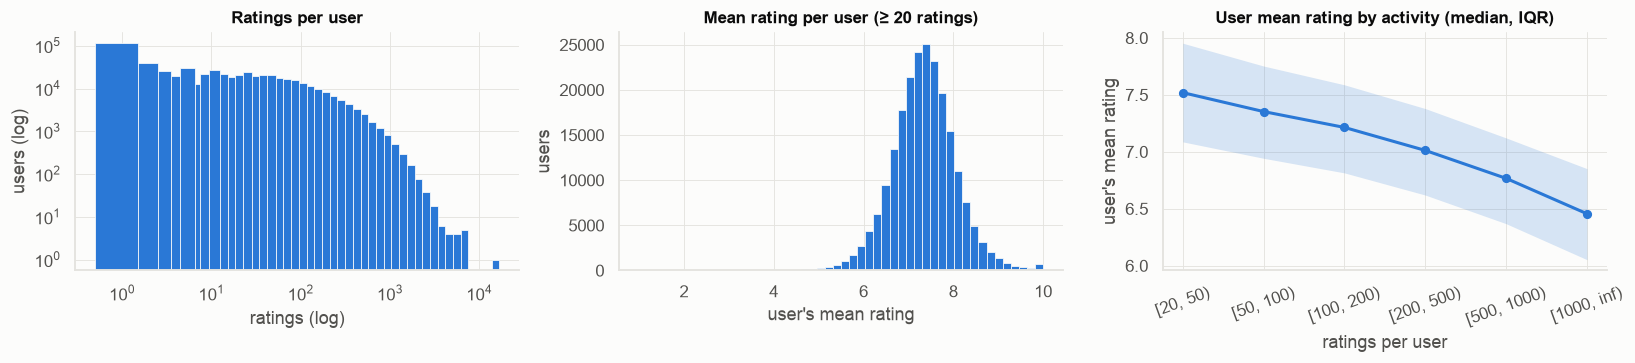

In [9]:
users = analysis.user_stats(d.new.ratings)
figures.users(users, analysis.generosity_by_activity(users, cfg.frame.min_user_ratings), cfg.frame.min_user_ratings)
facts(analysis.user_summary(users, cfg.frame.min_user_ratings),
      formats={"share who rated a single game": "share", "median ratings per user": "count", "90th percentile": "count"})
show(users.nlargest(6, "n"), "Most active users", formats={"mean": "rating", "std": "rating"})

### 2.3 Item characteristics: popularity and the long tail

,value
"share of ratings held by the 2,000 most-rated games",72.4%
those games as a share of all games,7.2%
Spearman correlation of popularity and mean rating,0.247


,name,n,mean,yearpublished
ID,,,,
13,CATAN,"131,302",7.14,1995
822,Carcassonne,"131,204",7.41,2000
30549,Pandemic,"128,952",7.53,2008
68448,7 Wonders,"107,527",7.67,2010
167791,Terraforming Mars,"103,950",8.35,2016
266192,Wingspan,"100,041",8.03,2019
173346,7 Wonders Duel,"99,667",8.09,2015
230802,Azul,"96,517",7.73,2017


,name,n,mean,yearpublished
ID,,,,
251661,Oathsworn: Into the Deepwood,"5,569",8.90,2022
295770,Frosthaven,"7,997",8.80,2022
397598,Dune: Imperium – Uprising,"9,496",8.73,2023
383179,Age of Innovation,"5,683",8.60,2023
224517,Brass: Birmingham,"50,029",8.58,2018
233078,Twilight Imperium: Fourth Edition,"25,325",8.58,2017
174430,Gloomhaven,"64,039",8.57,2017
115746,War of the Ring: Second Edition,"22,657",8.55,2011


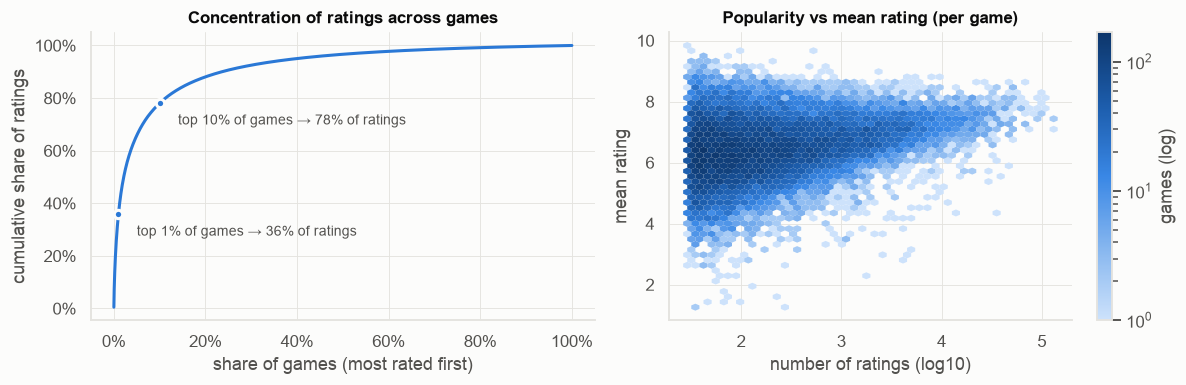

In [10]:
curve = analysis.concentration(games)
figures.long_tail(curve, games)
facts(analysis.popularity_facts(games, curve, cfg.frame.n_games), formats={
    f"share of ratings held by the {cfg.frame.n_games:,} most-rated games": "share", "those games as a share of all games": "share"})
columns, formats = ["name", "n", "mean", "yearpublished"], {"mean": "rating", "yearpublished": "year"}
show(games.nlargest(8, "n")[columns], "Most rated games", formats=formats)
show(games[games.n >= 5_000].nlargest(8, "mean")[columns], "Highest mean rating (≥ 5,000 ratings)", formats=formats)

### 2.4 Item characteristics: what kind of games get rated higher?

,value
correlation of complexity and mean rating (games ≥ 100 ratings),0.557


popularity,least rated quarter,2nd,3rd,most rated quarter
era,,,,
before 2000,6.06,6.14,6.28,6.51
2000–2014,6.02,6.12,6.30,6.81
2015–2019,6.48,6.54,6.70,7.11
2020+,7.02,7.01,7.17,7.43


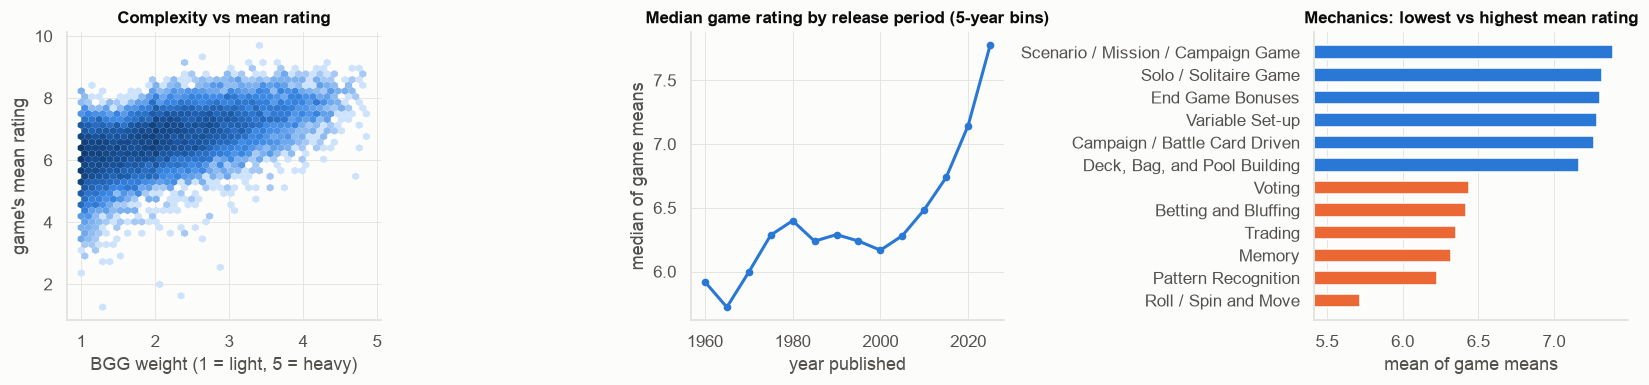

In [11]:
figures.item_characteristics(games, analysis.rating_by_period(games), analysis.mechanic_ratings(games, d.games))
facts({"correlation of complexity and mean rating (games ≥ 100 ratings)": analysis.complexity_correlation(games)})
show(analysis.rating_by_era_and_popularity(games), "Median game rating by era and popularity (games ≥ 100 ratings)", default="rating")

### 2.5 Rating drift: how re-rated games changed between 2022 and 2025

,value
re-rated pairs,"959,995"
mean change,-0.43
share that went down,67.7%
share that went up,32.3%


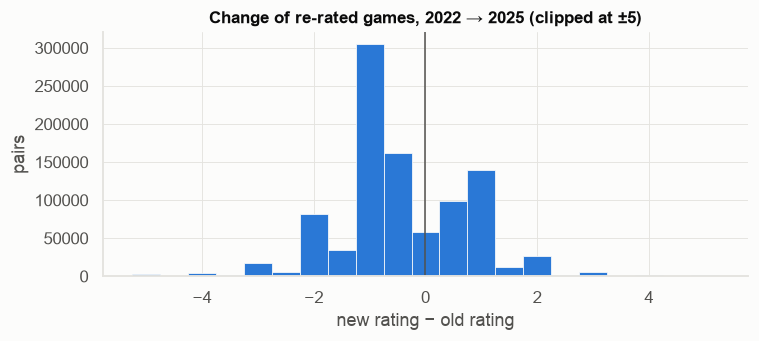

In [12]:
delta = analysis.rerating_drift(d.diff)
figures.drift(delta)
facts(analysis.drift_summary(delta), formats={"mean change": "signed rating", "share that went down": "share", "share that went up": "share"})

### 2.6 EDA takeaways

1. **Ratings are skewed high.** Mean 7.13, two thirds of all ratings are between 6 and 8, and 39% are ≥ 8. "Liked" (≥ 8) therefore means roughly the top 40% of a user's ratings, and predicting the global mean for everything already gives an RMSE of about 1.5.
2. **Users differ in generosity, and heavy users are harsher.** User means spread over about two points of the scale, and the median user mean drops from 7.5 (20–50 ratings) to about 6.5 (1,000+ ratings). Models need user biases (or mean-centring) before they can learn taste.
3. **Extreme long tail on both sides.** The median user rated 11 games and 21% rated only one. The 2,000 most-rated games (7% of the catalogue) hold 72% of all ratings. This justifies modelling on a dense core, and it warns that popularity will be hard to beat in any top-N evaluation.
4. **Newer and heavier games are rated higher, at every level of popularity.** Popularity barely predicts quality (Spearman 0.25), but complexity does (r = 0.56). In the era × popularity table, games from 2020+ are rated about a point higher than pre-2000 games in every popularity quarter (7.02 vs 6.06 among the least-rated). Campaign, solo and variable-set-up mechanics rate highest, roll-and-move lowest. This recency effect returns in section 4: rating models favour recent, highly rated games.
5. **Opinions cool over time.** Of the 960k ratings that changed between 2022 and 2025, 68% went down (mean change −0.43).
6. **Few data-quality problems.** 12 corrupt ratings and 66 missing usernames were removed, there are no duplicates, and the 435 users who gave every game the same rating are kept: too few to matter.

## 3. Building the Recommender System
### 3.1 The models

| Family | Models | Question it answers |
|---|---|---|
| Baselines | Global mean, random (`NormalPredictor`), `BaselineOnly` (μ + b<sub>u</sub> + b<sub>i</sub>) | what can be predicted without any personal taste? |
| Item-based KNN | four variants with the same similarity (`pearson_baseline`) and *k* = 40, differing **only in normalisation**: raw ratings (`KNNBasic`), mean-centred (`KNNWithMeans`), z-scored (`KNNWithZScore`), baseline-adjusted (`KNNBaseline`) | does normalisation matter? |
| User-based KNN | `KNNBaseline` over the 40 most similar users (a 15,000 × 15,000 similarity matrix, the slowest model) | users or items as neighbours? |
| Matrix factorisation | `SVD` (default and tuned): r̂<sub>ui</sub> = μ + b<sub>u</sub> + b<sub>i</sub> + q<sub>i</sub>·p<sub>u</sub>; `SVD++`: SVD plus implicit feedback (the *fact* that a user rated a game) | do latent taste factors help? |
| Ensemble | the average of tuned SVD and the best item-KNN | do two kinds of model combine? |
| Lists | **Popularity** (the most-rated games); **co-rating item-KNN** (Deshpande & Karypis 2004: games are similar when the same users rated both; a user's score sums the similarities to the games they **liked**, ≥ 8); **EASE** (Steck 2019: the same idea with item-to-item weights **learned** by a closed-form ridge regression) | which games will a user play and love? |

Rating models predict *how much* a user would like a game; for lists they score every game with their own prediction formula. The list models learn "people who played X also played Y", which captures what people choose to play as well as what they enjoy.

### 3.2 Tuning item-KNN

Grid search over *k* and the similarity measure, with 3-fold cross-validation **on the training set only**, so the test sets stay untouched. Similarities between games are estimated from the users who rated both, so it matters how much evidence each pair has.

In [13]:
knn = tuning.tune_item_knn(cfg.frame, cfg.grids)
show(knn.table, "Item-KNN grid (3-fold CV on training data)", default="rmse", formats={"k": "count"})
facts(analysis.shared_raters(frame), formats={
    "median users who rated both games of a pair": "count", "share of pairs with fewer than 20": "share", "share of pairs with fewer than 5": "share"})

,k,similarity,CV RMSE,CV RMSE std
5,40,pearson_baseline,1.1997,0.0007
8,80,pearson_baseline,1.2000,0.0008
2,20,pearson_baseline,1.2016,0.0004
6,80,msd,1.2052,0.0008
3,40,msd,1.2053,0.0009
0,20,msd,1.2115,0.0009
7,80,cosine,1.2128,0.0007
4,40,cosine,1.2132,0.0009
1,20,cosine,1.2202,0.0008


,value
median users who rated both games of a pair,20
share of pairs with fewer than 20,49.7%
share of pairs with fewer than 5,9.4%


### 3.3 Tuning SVD

**How many epochs?** A learning curve on a validation part (10%) of the training data, for Surprise's default regularisation and a stronger one. Then a grid search over the number of factors and the regularisation strength at the chosen number of epochs (learning rate 0.005), 3-fold cross-validation on the training data.

,n_factors,reg_all,CV RMSE,CV RMSE std
13,300,0.1000,1.1903,0.0006
9,200,0.1000,1.1909,0.0002
5,100,0.1000,1.1931,0.0003
14,300,0.1500,1.1962,0.0005
1,50,0.1000,1.1962,0.0003
10,200,0.1500,1.1965,0.0002
6,100,0.1500,1.1975,0.0003
2,50,0.1500,1.1996,0.0003


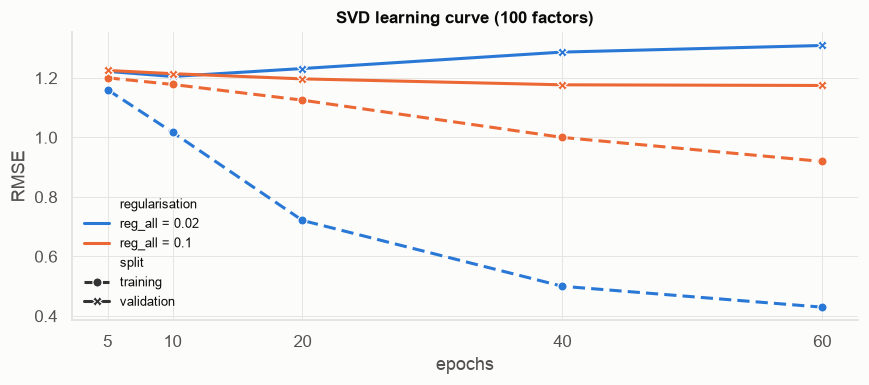

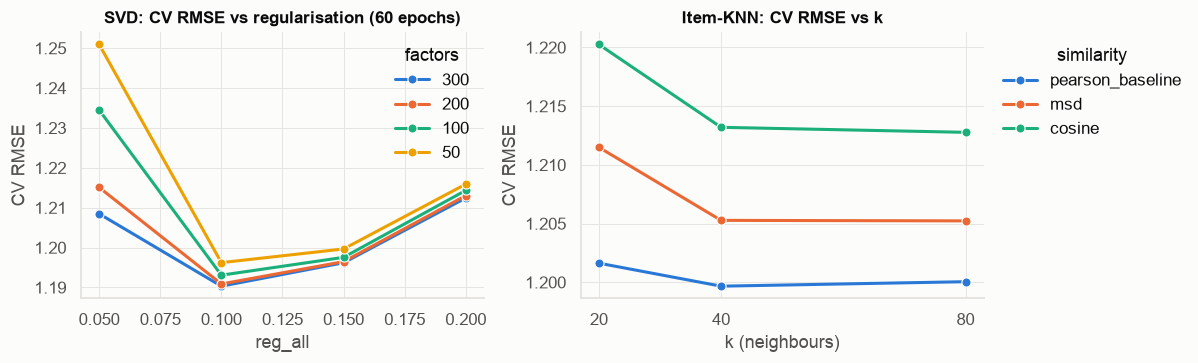

In [14]:
curve = tuning.svd_learning_curve(cfg.frame, cfg.grids)
figures.learning_curve(curve.table)
svd_search = tuning.tune_svd(cfg.frame, cfg.grids, curve.best["n_epochs"])
figures.tuning(svd_search.table, knn.table, curve.best["n_epochs"])
show(svd_search.table.head(8), f"SVD grid: best 8 of {len(svd_search.table)} (3-fold CV on training data)", default="rmse", formats={"n_factors": "count"})

**Tuning result.** For item-KNN, `pearson_baseline` beats `msd` and `cosine` at every *k*, and *k* = 40 is the optimum, which is Surprise's default. Shrinkage matters here because the evidence per pair of games is thin: half of all game pairs share fewer than 20 raters. For SVD, the learning curve shows Surprise's default regularisation (0.02) **overfitting** after about 10 epochs (training error keeps falling while validation error rises), while the stronger regularisation (0.1) keeps improving up to 60 epochs. The grid then confirms 0.1 as the best regularisation for every number of factors (both 0.05 and 0.15 are worse); 300 factors win, but by less than the variation between folds.

### 3.4 Tuning EASE

The regularisation strength, and whether its input is the games a user liked or all the games they rated, chosen by precision@10 on the validation split.

In [15]:
ease_search = tuning.tune_ease(cfg.frame, cfg.grids, liked, k)
show(ease_search.table.pivot(index="reg", columns="input", values=f"validation P@{k}"), f"EASE: P@{k} on the validation split", default="rmse")
tuned = Tuned(knn=knn.best, svd=svd_search.best, ease=ease_search.best)
facts({"item-KNN": tuned.knn, "SVD": {p: v for p, v in tuned.svd.items() if p != "random_state"}, "SVD epochs": curve.best["n_epochs"],
       "EASE": tuned.ease}, "Chosen settings")

input,all rated games,liked games
reg,,
100,0.0550,0.0612
300,0.0575,0.0626
500,0.0582,0.0625
1000,0.0582,0.0617
3000,0.0562,0.0583


,value
item-KNN,"{'k': 40, 'verbose': False, 'sim_options': {'name': 'pearson_baseline', 'user_based': False}}"
SVD,"{'n_factors': 300, 'reg_all': 0.1, 'n_epochs': 60, 'lr_all': 0.005}"
SVD epochs,60
EASE,"{'reg': 300.0, 'liked_threshold': 8.0}"


Using only the games a user **liked** as EASE's input is better than using every rated game, at every regularisation strength; the regularisation itself matters little between 300 and 1,000.

### 3.5 Training every model once

Each rating model is fitted on the training ratings and predicts both test sets; the list models are fitted on the same ratings. The check confirms that the fast vectorised scores used for ranking reproduce Surprise's own predictions.

In [16]:
ITEM_KNN = best_item_knn(tuned)
rated = evaluation.evaluate_rating_models(frame, rating_models(tuned, seed), seed)
rated = evaluation.with_average(rated, frame, Name.AVERAGE, of=(Name.SVD_TUNED, ITEM_KNN))
scorers = list_scorers(frame.ratings, rated.fitted, tuned, liked, seed)
facts(verify_rating_scorers(rated.fitted, scorers), "Vectorised scores vs Surprise", default="scientific")

Global mean                              RMSE random 1.5162   future 1.4397   fit    0s


Random (NormalPredictor)                 RMSE random 2.1152   future 2.0621   fit    0s


BaselineOnly                             RMSE random 1.2166   future 1.2655   fit    1s


Item-KNN: raw ratings (KNNBasic)         RMSE random 1.2522   future 1.3294   fit    5s


Item-KNN: mean-centred (KNNWithMeans)    RMSE random 1.1766   future 1.2780   fit    5s


Item-KNN: z-scored (KNNWithZScore)       RMSE random 1.1766   future 1.2769   fit    5s


... (2 outputs left out)

SVD (default)                            RMSE random 1.2274   future 1.2981   fit    8s


SVD (tuned)                              RMSE random 1.1714   future 1.2471   fit   44s


SVD++ (default)                          RMSE random 1.2175   future 1.3144   fit   66s


,value
BaselineOnly: max |vectorised − Surprise|,0.0e+00
SVD (default): max |vectorised − Surprise|,1.8e-15
SVD (tuned): max |vectorised − Surprise|,1.8e-15
SVD++ (default): max |vectorised − Surprise|,8.9e-16


## 4. Evaluation
### 4.1 Rating accuracy: RMSE and MAE

Because only some users rated anything after 2022, the table also reports the random-split RMSE **on those same users**, which is the fair point of comparison for the future column.

,family,RMSE random,MAE random,RMSE random (future users),RMSE future,MAE future,fit (s),RMSE gain vs BaselineOnly
Average of SVD (tuned) and item-KNN,ensemble,1.166998,0.856509,1.155448,1.255436,0.901272,—,+4.1%
SVD (tuned),matrix factorisation,1.171394,0.860582,1.160092,1.247058,0.895681,44,+3.7%
Item-KNN: baseline (KNNBaseline),neighbourhood,1.175029,0.862290,1.162237,1.277873,0.918603,5,+3.4%
Item-KNN: z-scored (KNNWithZScore),neighbourhood,1.176592,0.863268,1.163949,1.276861,0.917288,5,+3.3%
Item-KNN: mean-centred (KNNWithMeans),neighbourhood,1.176633,0.864078,1.164028,1.277992,0.919738,5,+3.3%
User-KNN (KNNBaseline),neighbourhood,1.191112,0.877530,1.178786,1.260542,0.909542,51,+2.1%
BaselineOnly,baseline,1.216598,0.896451,1.206182,1.265541,0.911165,1,+0.0%
SVD++ (default),matrix factorisation,1.217468,0.894820,1.208156,1.314441,0.951224,66,-0.1%
SVD (default),matrix factorisation,1.227410,0.906309,1.219786,1.298115,0.940097,8,-0.9%
Item-KNN: raw ratings (KNNBasic),neighbourhood,1.252179,0.926271,1.238188,1.329427,0.966449,5,-2.9%


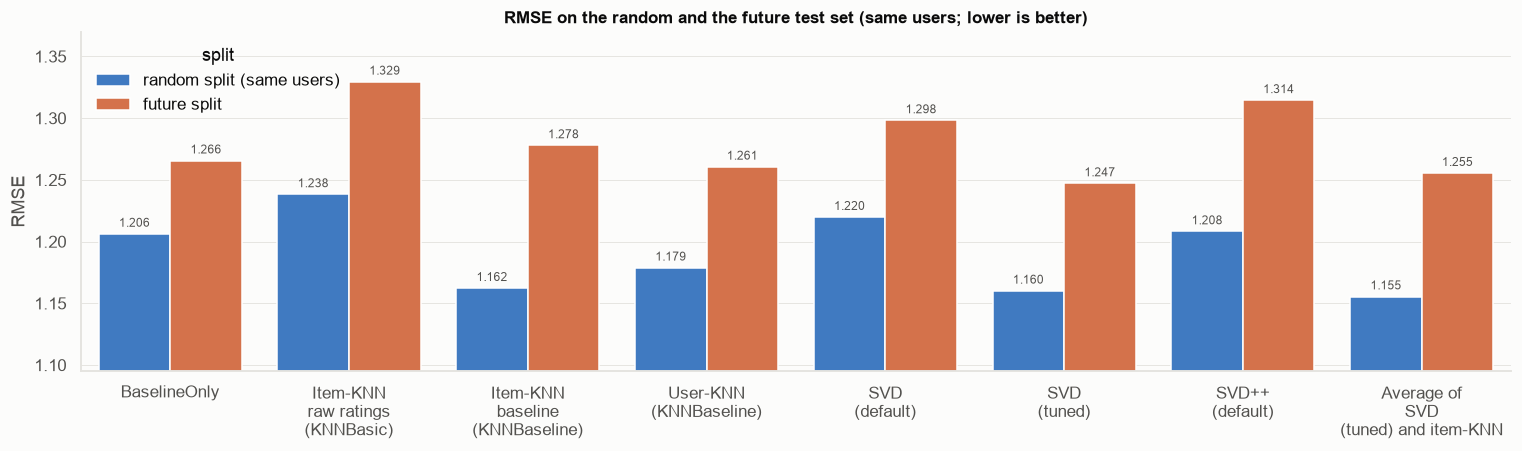

In [17]:
table = rated.table.assign(**{"RMSE gain vs BaselineOnly": rated.gain_over(Name.BASELINE)}).sort_values("RMSE random")
show(table, default="rmse", formats={"fit (s)": "count", "RMSE gain vs BaselineOnly": "signed share"})
figures.rmse(rated.table, [*pick.RMSE_CHART[:2], ITEM_KNN, *pick.RMSE_CHART[2:]])

**Reading the table.**
- **Most of the predictable signal is bias.** Going from the global mean (1.516) to `BaselineOnly` (1.217) removes 20% of the error, just by knowing how generous each user is and how good each game is.
- **Normalisation is essential; which kind barely matters.** Item-KNN on raw ratings (1.252) is *worse than `BaselineOnly`*; mean-centring, z-scoring and baseline adjustment all bring it to about 1.176. This is the measured answer to the assignment's "normalise the data".
- **Collaborative filtering adds a real but modest 3–4% on top of the biases.** Tuned SVD reaches **1.171**, item-KNN **1.175**, and their average **1.167** (+4.1%, the best).
- **Item-based beats user-based KNN** (1.175 vs 1.191), and is far cheaper: there are fewer games than users, and each game has many ratings, so game–game similarities are more reliable than user–user ones.
- **Untuned matrix factorisation overfits.** Default SVD (1.227) and SVD++ (1.218) do not beat `BaselineOnly`; the stronger regularisation found in 3.3 fixes this.
- **Every model is worse on the future** (right column). On the same users, tuned SVD goes from 1.160 to 1.247, and item-KNN falls *behind* `BaselineOnly` on the future (1.278 vs 1.266): its neighbourhoods memorise past co-rating patterns that do not carry over.

**Cross-validation (robustness).** One split can be lucky. 5-fold cross-validation on the whole 2022 sample, with **identical folds** for every model, so the models can also be compared fold by fold.

In [18]:
finalists = [m for m in rating_models(tuned, seed) if m.name in (Name.BASELINE, ITEM_KNN, Name.SVD_TUNED)]
cv = evaluation.cross_validate_models(frame, finalists, cfg.eval_folds, seed)
show(cv.table, default="rmse")
show(cv.folds, "RMSE per fold", default="rmse")
facts(cv.paired_test(Name.SVD_TUNED, ITEM_KNN), f"{Name.SVD_TUNED} vs {ITEM_KNN}, paired over folds",
      formats={"mean RMSE difference": "difference", "t": "rating", "p": "rmse"})

,RMSE mean,RMSE std,MAE mean,MAE std
BaselineOnly,1.2137,0.0022,0.8954,0.0016
Item-KNN: baseline (KNNBaseline),1.1720,0.0026,0.8611,0.0018
SVD (tuned),1.1681,0.0023,0.8594,0.0017


,BaselineOnly,Item-KNN: baseline (KNNBaseline),SVD (tuned)
0,1.2156,1.1751,1.1713
1,1.2148,1.1728,1.1686
2,1.2120,1.1698,1.1659
3,1.2160,1.1741,1.1696
4,1.2103,1.1683,1.1651


,value
mean RMSE difference,-0.0040
t,-18.25
p,0.0001
folds where SVD (tuned) is better,5


**Robustness.** Fold-to-fold variation is small (std about 0.002). The CF gain over `BaselineOnly` (about 0.045 RMSE) is some 20 times larger than that variation, so it is real. SVD beats item-KNN in **all 5 folds** (mean difference −0.0040, paired t-test p = 0.0001): consistently, if only slightly, better.

**Error analysis.** Where does the best single model go wrong?

,n,mean_prediction,RMSE
true rating,,,
1,"1,043",4.85,4.25
2,"1,697",5.46,3.70
3,"3,287",5.89,3.11
4,"7,063",6.08,2.28
5,"14,567",6.40,1.61
6,"45,504",6.75,0.95
7,"63,946",7.12,0.60
8,"77,230",7.52,0.74
9,"26,478",7.87,1.29


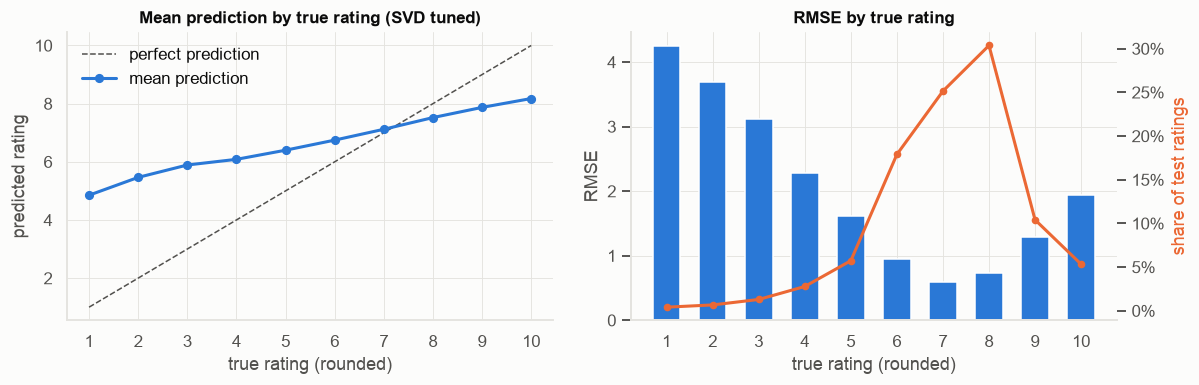

In [19]:
profile = metrics.error_profile(rated.predictions[Name.SVD_TUNED]["random"])
figures.error_profile(profile)
show(profile, formats={"mean_prediction": "rating", "RMSE": "rating"})

**Every rating is pulled towards the average.** A true 1 is predicted as 4.85 on average, a true 10 as 8.18; the error is smallest for the common ratings 6–8 and grows quickly at the extremes. A model that cannot tell a 10 from an 8 will struggle to find the games a user loves most, which is what section 4.2 measures.

### 4.2 Ranking quality: precision, recall and NDCG

RMSE measures how close the predicted *numbers* are, but a recommender shows a *list*. A game counts as relevant if the user rated it **≥ 8**. Two protocols:

**Method A (Surprise FAQ):** for each user, rank only the games in *their own test set*. Simple, but optimistic: the model only chooses among games the user is known to have played.

In [20]:
show(evaluation.within_test_table(rated, [*pick.WITHIN_TEST_RANKING, ITEM_KNN], k, liked), "Method A: ranking within each user's own test games")

,P@10,R@10
Random (NormalPredictor),0.423,0.272
BaselineOnly,0.495,0.254
SVD (tuned),0.527,0.295
SVD++ (default),0.594,0.384
Item-KNN: baseline (KNNBaseline),0.558,0.345


Method A looks flattering (precision 0.50–0.59), but even random predictions score 0.42. The model only re-orders games the user is *known* to have played, so precision mostly reflects how many of those games were liked. Method B is the realistic test.

**Method B (full catalogue):** for **every** test user with at least one liked held-out game, score **all catalogue games they haven't rated**, take the top 10, and count the liked held-out games among them. This is what a real recommender does. Metrics per user, then averaged:
- **P@10** (precision): share of the 10 that are hits; **R@10** (recall): share of the user's liked held-out games that appear;
- **NDCG@10**: like recall, but hits near the top count more; **HR@10** (hit rate): share of users with at least one hit.

The intervals are 95% bootstrap intervals over users. Comparisons between two models are **paired** (same users), which makes them much tighter.

,value
"users evaluated, random split","14,432"
"users evaluated, future split","7,036"
in both,"6,876"


,P@10,R@10,NDCG@10,HR@10,P@10 low,P@10 high
EASE,0.145,0.235,0.241,0.694,0.142,0.147
Co-rating KNN,0.118,0.193,0.195,0.621,0.115,0.120
Co-rating KNN (all rated games),0.109,0.180,0.182,0.593,0.107,0.112
Popularity,0.077,0.126,0.119,0.472,0.075,0.079
SVD++ (default),0.031,0.046,0.045,0.235,0.030,0.032
SVD (tuned),0.026,0.039,0.037,0.201,0.025,0.027
SVD (default),0.025,0.038,0.037,0.198,0.025,0.027
BaselineOnly,0.014,0.021,0.020,0.119,0.013,0.015
Random,0.004,0.006,0.005,0.038,0.004,0.004


,Δ P@10,95% CI low,95% CI high,significant
comparison,,,,
EASE − Co-rating KNN,+0.0269,+0.0255,+0.0284,yes
EASE − Popularity,+0.0678,+0.0659,+0.0697,yes
Co-rating KNN − Popularity,+0.0408,+0.0394,+0.0423,yes
Co-rating KNN − SVD++ (default),+0.0869,+0.0848,+0.0890,yes
SVD++ (default) − Popularity,-0.0460,-0.0478,-0.0442,yes
SVD (tuned) − SVD (default),+0.0005,-0.0004,+0.0014,no
Co-rating KNN − Co-rating KNN (all rated games),+0.0084,+0.0075,+0.0092,yes


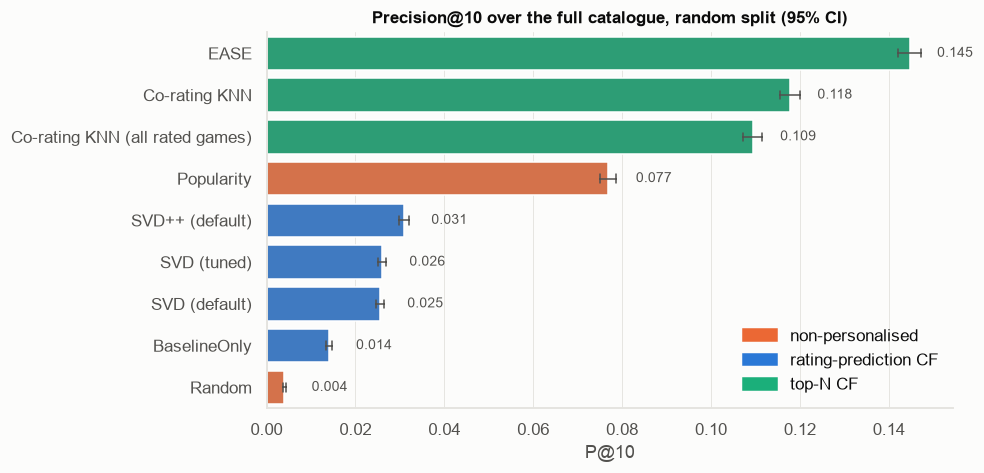

In [21]:
tasks = evaluation.ranking_tasks(frame, liked)
ranked = evaluation.evaluate_rankings(scorers, tasks, k, cfg.bootstrap_resamples, seed)
facts({"users evaluated, random split": len(tasks["random"]), "users evaluated, future split": len(tasks["future"]), "in both": len(ranked.same_users)})
show(ranked.summary("random").sort_values(f"P@{k}", ascending=False), f"Method B, random split: top-{k} over the full catalogue")
differences = {f"Δ P@{k}": "difference", "95% CI low": "difference", "95% CI high": "difference"}
show(ranked.compare("random", pick.COMPARE_RANDOM), "Paired differences, random split", formats=differences)
figures.precision(ranked.tidy(["random"], ranked.models), {str(m): list_group(m) for m in ranked.models}, k, cfg.bootstrap_resamples, seed)

**Result.** The ranking reverses the RMSE table:
- **EASE** reaches **P@10 = 0.145, R@10 = 0.235, and a hit rate of 69%**: for 69% of users, at least one of the 10 suggestions (out of about 1,900 candidates) is a game they really played and loved.
- The simpler **co-rating KNN** is next (0.118), then **popularity** (0.077).
- **Every rating-prediction model is far below popularity** (SVD++ 0.031, tuned SVD 0.026, `BaselineOnly` 0.014). Tuning SVD for RMSE does not change its precision (+0.0005, not significant).
- EASE's lead over the co-rating KNN (+0.027) and popularity (+0.068) is clearly significant; liking-weighted input beats all-rated input for the co-rating model too (+0.008).

Absolute precision is low for every model because only *observed* ratings count as hits: a game the user would love but has not played yet counts as a miss. The comparison between models is what matters.

**Why do rating models make poor lists?** Look at *what* they recommend, compared with what users actually rate.

In [22]:
items = analysis.item_table(frame, d, games)
show(analysis.recommendation_profile({str(m): ranked.lists["random", m] for m in pick.WHAT_GETS_RECOMMENDED}, items, frame, tasks["random"].users),
     "What gets recommended vs what users rate (random split)", formats={"median year": "year", "mean weight": "rating", "mean popularity percentile": "count"})
bias_formats = {"b_i": "signed rating", "year": "year", "ratings in training": "count"}
show(analysis.biases(rated.fitted[Name.SVD_TUNED], items).nlargest(8, "b_i"), "Highest item biases in SVD (tuned)", formats=bias_formats)

,median year,mean weight,mean popularity percentile
(games users actually rate),2012,2.36,76
Popularity,2009,2.28,100
BaselineOnly,2019,3.61,66
SVD (tuned),2018,3.52,66
SVD++ (default),2017,3.49,73
Co-rating KNN,2011,2.54,98
EASE,2012,2.81,96


,game,b_i,year,ratings in training
ID,,,,
266507,Clank! Legacy: Acquisitions Incorporated,+1.21,2019,378
246900,Eclipse: Second Dawn for the Galaxy,+1.20,2020,378
224517,Brass: Birmingham,+1.17,2018,"1,750"
174430,Gloomhaven,+1.11,2017,"2,703"
235802,Too Many Bones: Undertow,+1.08,2018,164
233078,Twilight Imperium: Fourth Edition,+1.06,2017,962
324856,The Crew: Mission Deep Sea,+1.05,2021,230
284378,Kanban EV,+1.05,2020,239


**Why do rating models lose?** They answer a different question. A rating model predicts *how much* a user would like a game *if* they played it; it never learns *which* games a user is likely to play. Two consequences show in the tables:
- **Ratings are missing not at random.** People play and rate what they hear about, so most of the hidden liked games are popular ones (users' own games sit at the 76th popularity percentile). Popularity captures that, and so do the list models (96th–98th percentile).
- **Rating models favour recent, heavy, highly rated games.** Their lists have a median year of 2017–2019 and a mean complexity of 3.5–3.6, against 2012 and 2.36 for what users actually rate. These are the games with the highest item bias b<sub>i</sub> (*Clank! Legacy*, *Eclipse: Second Dawn*, *Brass: Birmingham*, *Gloomhaven*): rated mostly by the fans who sought them out, so the bias pushes them to the top of almost everyone's list.

Optimising RMSE is not the same as optimising a top-N list (Cremonesi, Koren & Turrin, *Performance of Recommender Algorithms on Top-N Recommendation Tasks*, RecSys 2010).

**Do the results hold for obscure games, for users with short histories, and for other definitions of "liked"?**
- *Long tail:* the most popular games, which together hold a third of all training ratings, are removed from both the candidates and the relevant games.
- *History length:* the random-split results split by the number of training ratings per user.
- *Threshold:* "liked" redefined as ≥ 7 and ≥ 9 (the co-rating model and EASE use the same threshold).

In [23]:
show(evaluation.breakdowns(frame, ranked, scorers, rated.fitted, tuned, pick.BREAKDOWNS, cfg), f"P@{k} in sub-groups and with other thresholds (random split)")

,Popularity,SVD (tuned),SVD++ (default),Co-rating KNN,EASE
"long tail (133 head games removed; 12,646 users)",0.017,0.014,0.015,0.050,0.079
"history 0–39 ratings (6,795 users)",0.048,0.014,0.017,0.072,0.087
"history 40–119 ratings (5,592 users)",0.078,0.028,0.031,0.123,0.154
"history ≥ 120 ratings (2,045 users)",0.171,0.062,0.077,0.257,0.311
"liked = rating ≥ 7 (14,903 users)",0.121,0.028,0.035,0.168,0.206
"liked = rating ≥ 9 (11,636 users)",0.039,0.023,0.025,0.068,0.083


**The ranking holds everywhere.** EASE is best on obscure games (with the 133 most popular games removed: 0.079 vs 0.017 for popularity), for users with short histories (fewer than 40 ratings: 0.087 vs 0.048), for heavy users (0.311 vs 0.171), and with "liked" defined as ≥ 7 or ≥ 9. Rating models stay below popularity even on the long tail, so their problem is not only popularity: within obscure games they still pick the wrong ones.

### 4.3 Random split vs the future

A random split hides a random 20% of each user's *past* ratings. The future test set asks the harder, real question: **which games will the user rate next?** The fair comparison uses the **same users** in both columns.

,P random,P future,NDCG random,NDCG future,HR random,HR future
Random,0.005,0.005,0.007,0.006,0.048,0.047
Popularity,0.090,0.039,0.121,0.048,0.508,0.273
BaselineOnly,0.021,0.054,0.029,0.078,0.179,0.362
SVD (tuned),0.038,0.063,0.051,0.087,0.280,0.397
SVD++ (default),0.042,0.053,0.057,0.073,0.306,0.357
Co-rating KNN,0.136,0.061,0.201,0.082,0.658,0.372
EASE,0.170,0.087,0.255,0.119,0.736,0.492


,Δ P@10,95% CI low,95% CI high,significant
comparison,,,,
EASE − SVD (tuned),+0.0246,+0.0220,+0.0274,yes
EASE − Co-rating KNN,+0.0258,+0.0239,+0.0279,yes
SVD (tuned) − Co-rating KNN,+0.0012,-0.0014,+0.0039,no
Co-rating KNN − Popularity,+0.0219,+0.0200,+0.0237,yes
SVD (tuned) − Popularity,+0.0231,+0.0205,+0.0256,yes
SVD (tuned) − BaselineOnly,+0.0085,+0.0069,+0.0101,yes


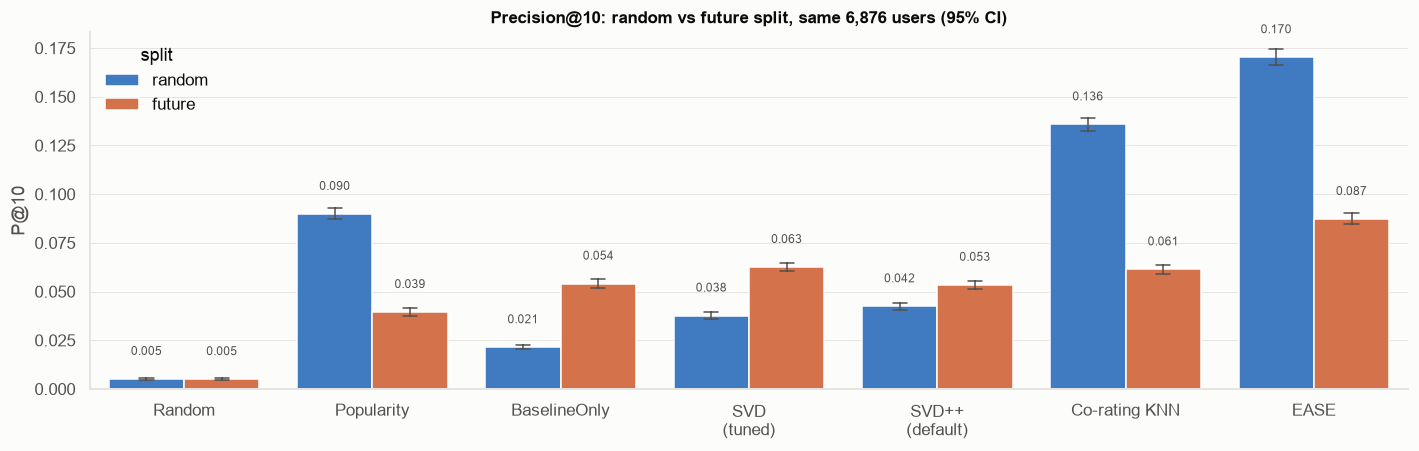

In [24]:
show(evaluation.random_vs_future_table(ranked, pick.RANDOM_VS_FUTURE), f"Same {len(ranked.same_users):,} users, random vs future")
show(ranked.compare("future", pick.COMPARE_FUTURE, ranked.same_users), "Paired differences, future split", formats=differences)
figures.random_vs_future(ranked.tidy(SPLITS, pick.RANDOM_VS_FUTURE, ranked.same_users), [str(m) for m in pick.RANDOM_VS_FUTURE],
                         k, cfg.bootstrap_resamples, seed, len(ranked.same_users))

**What changes when we predict the future**
- **Popularity goes stale.** The 2022 bestseller list drops from 0.090 to 0.039 on the same users, the largest relative fall.
- **The co-rating KNN's large lead disappears.** On the random split it is 3.6× better than SVD; on the future the two are statistically tied (+0.001, 95% CI [−0.001, +0.004]).
- **Rating models improve, because what users rate next is newer.** `BaselineOnly` rises from 0.021 to 0.054 and SVD from 0.038 to 0.063: the high-b<sub>i</sub>, recent games they favour are exactly what users go on to play.
- **EASE is the only model that stays clearly ahead on both test sets**: 0.170 random, 0.087 future, with a hit rate of 49% on the future (+0.025 over SVD, +0.026 over the co-rating KNN, both significant).

**Lesson:** a random split overstates how good popularity-like models are and understates rating models, so **which model looks best depends on the split**. Evaluating on time-ordered data matters.

**How much of the future could a model trained in 2022 recommend at all?**

In [25]:
facts(analysis.reachability(d, frame, liked), formats={
    "share on catalogue games": "share", f"share of liked (≥ {liked:g}) on catalogue games": "share",
    "mean rating, their 2022 ratings": "rating", "mean rating, their new ratings": "rating"})
show(analysis.most_rated_new_games(d, frame), "Most-rated games among the sampled users' new ratings", formats={"year": "year", "popularity rank in 2022": "count"})

,value
ratings added after Jan 2022,366427.000
share on catalogue games,44.8%
share of liked (≥ 8) on catalogue games,46.8%
"mean rating, their 2022 ratings",7.18
"mean rating, their new ratings",7.13


,game,new ratings,year,popularity rank in 2022,in catalogue
ID,,,,,
342942,Ark Nova,"2,514",2021,"2,008",False
295947,Cascadia,"1,919",2021,774,True
366013,Heat: Pedal to the Metal,"1,595",2022,—,False
316554,Dune: Imperium,"1,527",2020,220,True
312484,Lost Ruins of Arnak,"1,341",2020,183,True
291453,SCOUT,"1,086",2019,"4,734",False
266192,Wingspan,"1,027",2019,20,True
350184,Earth,990,2023,—,False


**Most of the future is out of reach.** Only 45% of what the sampled users rated after January 2022 is in the 2022 catalogue. The most-rated new game, **Ark Nova**, ranked #2,008 by popularity in 2022 and just missed the top-2,000 cut; *Heat* and *Earth* did not exist yet. A real system has to be retrained regularly, and needs a content-based fallback (mechanics, designer, complexity) for games that are too new to have ratings.

## 5. Making Recommendations
### 5.1 Top-10 lists for contrasting users

The best rating model in Method B (SVD++) next to the best list model (EASE), for three kinds of users from the evaluation set: a **heavy-strategy fan** and a **light / family gamer** (highest and lowest average complexity of the games they love, among users with ≥ 30 training ratings), and a user with a **short history**. ✓ marks a game the user really rated ≥ 8 in the held-out test set; "because you liked" names the liked game that contributes most to the EASE recommendation.

In [26]:
loved = analysis.loved_weight(frame, items, liked)
ease = scorers[Name.EASE]
for label, u in analysis.example_users(frame, tasks["random"].users, loved, cfg.min_user_ratings_for_examples).items():
    print(f"\n=== {label}: {frame.trainset.to_raw_uid(u)} ({frame.history_length[u]} training ratings, mean weight of loved games {loved[u]:.2f}) ===")
    show(analysis.favourites(frame, u, items), formats={"their rating": "rating", "weight": "rating"})
    lists = {str(m): ranked.lists["random", m][u] for m in pick.EXAMPLE_LISTS}
    show(analysis.lists_side_by_side(lists, tasks["random"].relevant[u], items, explain=(str(Name.EASE), lambda j, u=u: ease.because_of(u, j))),
         formats={(str(m), "weight"): "rating" for m in pick.EXAMPLE_LISTS})


=== heavy-strategy fan: raminshams (96 training ratings, mean weight of loved games 4.33) ===


,favourite game,their rating,weight
0,Through the Ages: A New Story of Civilization,8.50,4.44
1,Food Chain Magnate,8.20,4.20
2,Kanban: Driver's Edition,8.00,4.36
3,Blackout: Hong Kong,7.95,3.47
4,Battle Line,7.90,1.89



=== light / family gamer: girlswhogame (44 training ratings, mean weight of loved games 1.31) ===


,favourite game,their rating,weight
0,Secret Hitler,10.00,1.74
1,Splendor,10.00,1.78
2,Cards Against Humanity,10.00,1.18
3,Throw Throw Burrito,10.00,1.11
4,5-Minute Dungeon,10.00,1.12



=== short history: yury1975 (10 training ratings, mean weight of loved games 2.93) ===


,favourite game,their rating,weight
0,Arkham Horror: The Card Game,10.00,3.55
1,Tragedy Looper,9.00,3.55
2,Dawn of the Zeds (Third Edition),9.00,3.81
3,The Resistance,8.50,1.59
4,Space Hulk: Death Angel – The Card Game,8.00,2.41


**What the lists show.**
- **The light / family gamer** (loved games average weight 1.31: *Throw Throw Burrito*, *Splendor*, *Secret Hitler*) gets heavy, niche games from SVD++ (*Shadows of Brimstone*, *Etherfields*, *Twilight Imperium*), and from EASE exactly their kind of game: *Codenames*, *Ticket to Ride* (a hit), *Dixit*, *Skull*, *Decrypto*, each explained by a game they liked.
- **The heavy-strategy fan** gets heavy games from both; EASE's come from the same economic-euro family as *Food Chain Magnate* and *Through the Ages* (*Lisboa*, *Mombasa*, *Russian Railroads*).
- **The user with 10 ratings** gets from EASE the cooperative and hidden-role games their few favourites point to (*Mansions of Madness*, *Avalon*, *Eldritch Horror*, a hit), and from SVD++ a generic list of highly rated games.

Three users are anecdotes. Across **all** evaluated users: does the complexity of the recommendations follow the complexity of the games each user loves?

In [27]:
show(analysis.complexity_fit({str(m): ranked.lists["random", m] for m in pick.COMPLEXITY_FIT}, items, loved),
     "Complexity of recommendations vs complexity of loved games", default="rating")

,correlation with loved weight,mean |gap| (weight points)
Popularity,-0.35,0.49
SVD (tuned),0.41,0.92
SVD++ (default),0.47,0.90
Co-rating KNN,0.72,0.25
EASE,0.87,0.26


**Across all 14,427 users** the pattern holds: the complexity of EASE's lists follows the complexity of the games each user loves (correlation 0.87, mean gap 0.26 weight points), the co-rating KNN nearly as well (0.72), the rating models much less (0.41–0.47, gaps of 0.9), and popularity not at all (−0.35).

### 5.2 If all we know is one game you love

The hardest case for a recommender, and an easy one to judge: a new user tells us a single game they love. Would our suggestions beat simply handing them **10 random strategy games**, or the **10 most popular strategy games**?

The test uses the future: for every sampled user who loved a strategy game in 2022, recommend 10 games from that one game alone, then count how many of them the user **went on to rate ≥ 8 after January 2022**. Games they had already rated in 2022 are excluded for every method. First for the fans of one well-known game, *Scythe*, then for every user's favourite strategy game.

In [28]:
strategy = np.flatnonzero(items.strategy.to_numpy())
one_game = {m: scorers[m] for m in pick.ONE_GAME}
groups = {"Scythe fans": evaluation.fans_of(frame, cfg.example_game, liked),
          "everyone's favourite strategy game": evaluation.favourites_among(frame, strategy, liked)}
show(evaluation.one_game_summary(frame, one_game, groups, strategy, cfg), f"Games among the {k} suggestions that the user went on to love (mean, 95% CI)")
from_scythe = evaluation.one_game_lists(one_game, frame.inner_item(cfg.example_game), strategy, frame.popularity, set(), k)
show(analysis.name_lists(from_scythe, items), "Suggestions from Scythe alone")

,"Scythe fans (2,305 users)","everyone's favourite strategy game (6,998 users)"
random strategy games,"0.09 [0.08, 0.09]","0.07 [0.07, 0.07]"
most popular strategy games,"0.50 [0.47, 0.53]","0.47 [0.45, 0.49]"
Co-rating KNN,"0.76 [0.71, 0.80]","0.61 [0.58, 0.63]"
EASE,"0.78 [0.74, 0.83]","0.60 [0.57, 0.62]"


,most popular strategy games,Co-rating KNN,EASE
1,Pandemic,Terraforming Mars,Terraforming Mars
2,CATAN,7 Wonders Duel,Viticulture Essential Edition
3,7 Wonders,Wingspan,Wingspan
4,Dominion,Azul,Blood Rage
5,Terraforming Mars,Codenames,7 Wonders Duel
6,Small World,Blood Rage,Gloomhaven
7,7 Wonders Duel,7 Wonders,Root
8,Agricola,Viticulture Essential Edition,Terra Mystica
9,Puerto Rico,Great Western Trail,Pandemic Legacy: Season 1
10,Power Grid,Pandemic,Azul


**From a single game, both list models beat the obvious alternatives.** For people who loved *Scythe*, 10 suggestions from EASE contain on average 0.78 games they went on to love, against 0.50 for the 10 most popular strategy games and 0.09 for 10 random strategy games: about **9× better than random and 55% better than the bestsellers**. Over everyone's favourite strategy game the order is the same (0.60–0.61 vs 0.47 vs 0.07). From one game alone the two list models are tied; EASE's advantage needs a longer history.

**Played together, or loved more?** A suggestion can come up because fans of a game *play* it a lot, or because they *love* it more than other people do. Over all 2025 ratings: among people who rated Scythe ≥ 8, how many played each suggested game, and did they love it more than everyone else does? (A descriptive check on all data, not an evaluation.)

In [29]:
lift = analysis.played_vs_loved(d.new.ratings, cfg.example_game, {m: frame.items[idx] for m, idx in from_scythe.items()}, d, liked)
show(lift, "Suggestions from Scythe: played by fans vs loved by fans", formats={
    "weight": "rating", "fans who played it": "share", "everyone who played it": "share", "fans who loved it": "share",
    "everyone who loved it": "share", "love lift": "signed percent"})

,game,weight,fans who played it,everyone who played it,fans who loved it,everyone who loved it,love lift,suggested by
0,Viticulture Essential Edition,2.89,35.9%,9.2%,74.4%,67.2%,+7%,"Co-rating KNN, EASE"
1,Blood Rage,2.89,34.2%,8.8%,70.4%,64.5%,+6%,"Co-rating KNN, EASE"
2,Great Western Trail,3.70,28.7%,7.5%,79.3%,73.5%,+6%,Co-rating KNN
3,Terraforming Mars,3.27,59.8%,18.7%,81.1%,76.4%,+5%,"most popular strategy games, Co-rating KNN, EASE"
4,Terra Mystica,3.97,29.3%,8.8%,72.3%,68.0%,+4%,EASE
5,Root,3.81,33.9%,10.0%,72.4%,68.6%,+4%,EASE
6,Wingspan,2.47,52.0%,18.0%,70.2%,67.6%,+3%,"Co-rating KNN, EASE"
7,7 Wonders Duel,2.23,49.8%,17.9%,72.4%,70.6%,+2%,"most popular strategy games, Co-rating KNN, EASE"
8,Gloomhaven,3.91,34.3%,11.5%,81.3%,79.9%,+1%,EASE
9,Pandemic Legacy: Season 1,2.83,30.0%,9.9%,81.6%,80.7%,+1%,EASE


**Played together is not the same as loved more.** *Azul* is suggested because Scythe fans play it a lot (47% of them, against 17% of all users), but they love it at exactly the average rate (56% vs 57%): a safe suggestion, not a tailored one. The tailored ones are games Scythe fans love *more* than everyone else: *Viticulture* (+7 points, same publisher as Scythe), *Blood Rage* (+6), *Terraforming Mars* (+5), *Terra Mystica* and *Root* (+4). The bestseller list contains the bad matches: Scythe fans like *CATAN* clearly less than average (26% vs 36%).

### 5.3 Beyond accuracy: coverage, novelty, diversity

For each model's top-10 lists (random split):
- **Coverage**: share of the 2,000 catalogue games that appear in at least one list.
- **Novelty**: mean −log₂(p<sub>i</sub>), where p<sub>i</sub> is the share of users who rated game *i*. Higher means less obvious.
- **Intra-list diversity**: 1 − mean Jaccard similarity of the mechanics and categories of the games within a list.
- **Personalisation**: 1 − mean overlap between the lists of two random users (0 = everyone gets the same list).

**Re-ranking for novelty:** the scores of the best list model (EASE) are penalised by popularity, z(score) − β·z(log popularity), and the curve shows what each step of β costs in precision.

,P@k,coverage,novelty (bits),intra-list diversity,personalisation
Random,0.004,100.0%,5.58,0.940,0.997
Popularity,0.077,3.2%,1.63,0.915,0.607
BaselineOnly,0.014,1.9%,4.84,0.894,0.158
SVD (tuned),0.026,28.7%,4.73,0.881,0.795
SVD++ (default),0.031,37.2%,4.34,0.874,0.903
Co-rating KNN,0.118,19.6%,2.04,0.908,0.841
EASE,0.145,34.0%,2.52,0.902,0.936


,P@k,coverage,novelty (bits),intra-list diversity,personalisation
β,,,,,
0.000000,0.145,34.0%,2.52,0.902,0.936
0.250000,0.145,38.6%,2.62,0.901,0.943
0.500000,0.145,45.2%,2.74,0.899,0.949
0.750000,0.143,55.7%,2.91,0.897,0.955
1.000000,0.136,67.8%,3.19,0.894,0.963


,value
novelty of the games users actually rate (bits),4.14


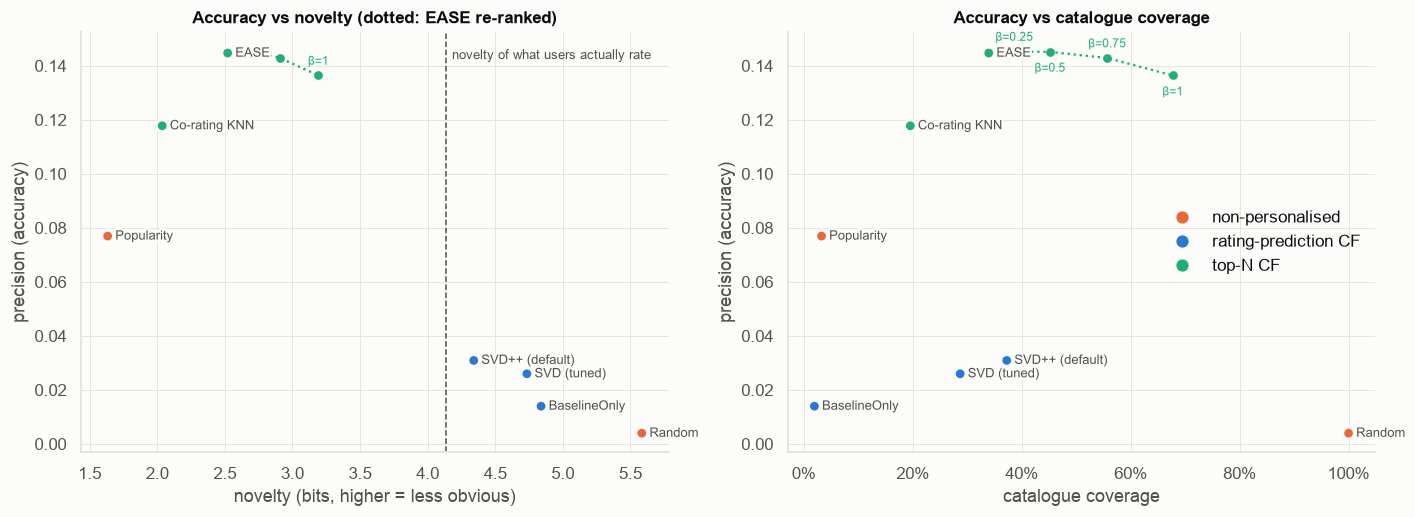

In [30]:
features = analysis.item_features(frame, d)
beyond = evaluation.beyond_accuracy_table(ranked, pick.BEYOND_ACCURACY, frame, features)
rerank = evaluation.rerank_sweep(ease, frame, tasks["random"], cfg.rerank_betas, k, features, seed)
own = analysis.own_novelty(frame, tasks["random"].users)
beyond_formats = {"coverage": "share", "novelty (bits)": "rating"}
show(beyond, formats=beyond_formats)
show(rerank, "EASE re-ranked with a popularity penalty β", formats=beyond_formats)
facts({"novelty of the games users actually rate (bits)": own}, formats={"novelty of the games users actually rate (bits)": "rating"})
figures.beyond_accuracy(beyond, rerank, own, {str(m): list_group(m) for m in pick.BEYOND_ACCURACY}, str(Name.EASE))

**The accuracy–novelty trade-off.**
- **The most accurate lists are mainstream.** EASE's novelty (2.52 bits) and the co-rating KNN's (2.04) are well below the novelty of what users actually rate (4.14): they recommend more popular games than people play, which reinforces popularity bias.
- **EASE is still far more personal and broad than the bestseller list.** It covers 34% of the catalogue (popularity: 3%), and two users' lists barely overlap (personalisation 0.94 vs 0.61).
- **Rating models are more novel (4.3–4.8 bits) but about 5× less accurate**, and `BaselineOnly` gives nearly everyone the same list (coverage 1.9%).
- **Re-ranking is free up to a point.** Penalising popularity with β = 0.5 raises EASE's coverage from 34% to 45% at an unchanged precision (0.145); β = 1 reaches 68% coverage and 3.19 bits for a 6% loss in precision.
- **Intra-list diversity hardly separates the models** (0.87–0.92; random lists 0.94): every list mixes several mechanics and categories.

## 6. Visualisation and Interpretation
### 6.1 User–item interactions
Left: the actual ratings of the 60 most active users on the 60 most-rated games of the frame (blank = not rated). Right: the whole 15,000 × 2,000 matrix compressed into blocks; colour shows the share of cells that hold a rating, with users sorted by activity and games by popularity.

,value
"fill rate, most active users × most-rated games",95%
"fill rate, least active × least rated",0.467%


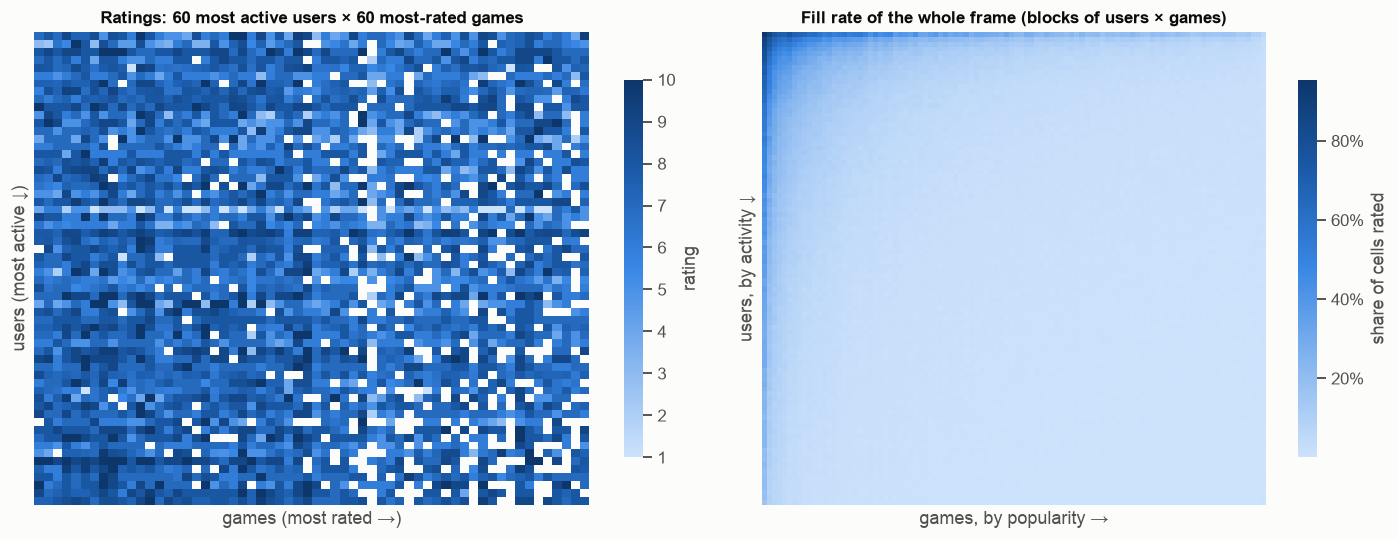

In [31]:
fill = analysis.fill_rate(frame)
figures.interactions(analysis.top_interactions(frame), fill)
facts({"fill rate, most active users × most-rated games": fill[0, 0], "fill rate, least active × least rated": fill[-1, -1]},
      formats={"fill rate, most active users × most-rated games": "percent", "fill rate, least active × least rated": "small share"})

Even inside the dense core, interactions are concentrated: the most active users have rated 95% of the most popular games, while the least active users and least popular games meet in 0.47% of cells. The heatmap also shows the user bias directly: some rows are uniformly darker (generous users) than others.

### 6.2 What did the SVD factors learn?

Each game has a vector q<sub>i</sub> of latent factors. Individual SVD factors are not unique: any rotation gives the same predictions. So we look at the **principal components** of the game vectors, the main directions along which games differ in who likes them, and correlate them with metadata the model **never saw**.

,low end,high end
PC1,Lisboa; Vinhos; Terra Mystica; Great Western Trail; Madeira; Food Chain Magnate,Bingo; Candy Land; Tic-Tac-Toe; Blackjack; Phase 10; Sorry!
PC2,Go; Napoleon's Triumph; Reef Encounter; Container: 10th Anniversary Jumbo Edition!; Stephenson's Rocket; Haggis,Fortune and Glory: The Cliffhanger Game; Etherfields; Pirate Fluxx; Arkham Horror; Red Rising; Tapestry


,PC1,PC2,PC3,PC4,PC5
averageweight,-0.69,+0.22,+0.16,-0.35,+0.14
playingtime,-0.50,+0.29,+0.14,-0.32,+0.13
yearpublished,-0.44,+0.26,-0.09,+0.27,-0.32
maxplayers,+0.24,+0.01,+0.04,+0.10,+0.01
mean rating,-0.79,+0.06,+0.07,+0.09,-0.15
log10 ratings,-0.26,+0.04,-0.08,+0.10,-0.16
Cooperative Game,-0.08,+0.17,+0.20,+0.17,-0.15
Worker Placement,-0.28,+0.11,-0.13,-0.17,-0.03
Dice Rolling,+0.01,+0.35,+0.12,-0.01,+0.01
"Deck, Bag, and Pool Building",-0.12,+0.14,+0.02,+0.01,-0.07


,value
PC1: share of the variance of the game vectors,0.049
PC2: share of the variance of the game vectors,0.035
PC3: share of the variance of the game vectors,0.027
PC4: share of the variance of the game vectors,0.025
PC5: share of the variance of the game vectors,0.020


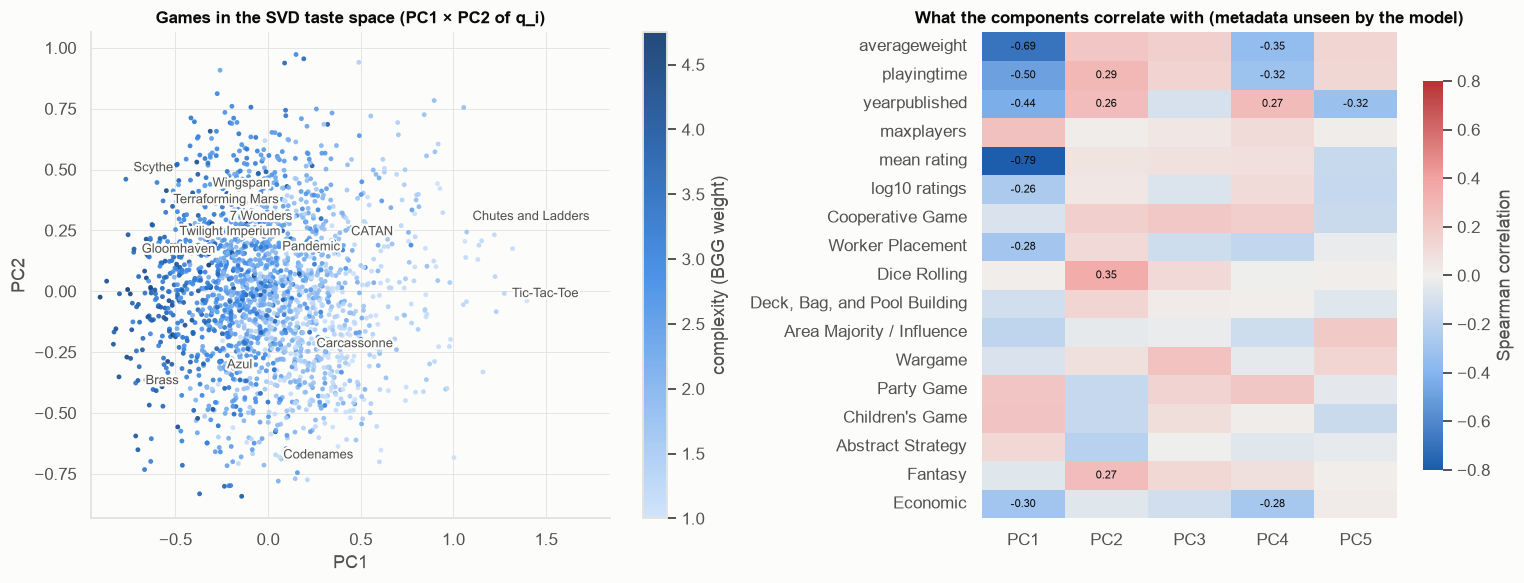

In [32]:
svd = rated.fitted[Name.SVD_TUNED]
components, correlations, explained = analysis.latent_components(svd, frame, d, games, seed=seed)
figures.taste_space(components, correlations, cfg.labelled_games)
show(pd.DataFrame([analysis.component_extremes(components, pc) for pc in ("PC1", "PC2")]), "The games at both ends of the first two components")
show(correlations, "Spearman correlation of each component with game metadata", default="signed rating")
facts({f"PC{i + 1}: share of the variance of the game vectors": v for i, v in enumerate(explained)})

**The model rediscovered the structure of the hobby from ratings alone.**
- **PC1 is a "hobbyist vs mass-market" axis.** It correlates with mean rating (−0.79), complexity (−0.69), play time (−0.50), release year (−0.44), economic games (−0.30) and worker placement (−0.28), and positively with children's and party games and the maximum number of players. Its ends: heavy euros (*Lisboa*, *Vinhos*, *Terra Mystica*, *Food Chain Magnate*) vs *Bingo*, *Candy Land*, *Tic-Tac-Toe*. (The sign of a component is arbitrary.)
- **PC2 is a "thematic vs abstract" axis.** One end has dice rolling (+0.35), fantasy (+0.27) and long play times (+0.29): *Arkham Horror*, *Etherfields*, *Fortune and Glory*. The other end has abstract strategy (−0.21) and older classics: *Go*, *Reef Encounter*, *Container*, *Stephenson's Rocket*.
- **PC3 leans towards wargames and cooperative games** (+0.23, +0.20).

Each component explains only 2–5% of the variance in the game vectors: taste is high-dimensional, so these are tendencies rather than hard clusters.

Do the factors capture the same thing on the **user** side? For every user, the factor part of their predicted ratings (q<sub>i</sub>·p<sub>u</sub>, biases left out) for heavy games (weight ≥ 3.5) minus light games, compared with the actual complexity of the games they love.

In [33]:
facts({"correlation of the factors' heavy-vs-light preference with the complexity of loved games":
       analysis.user_axis_check(svd, items, loved, cfg.heavy_weight, cfg.light_weight)})

,value
correlation of the factors' heavy-vs-light preference with the complexity of loved games,0.449


The same structure holds on the user side: users whose factors prefer heavy over light games are the ones who love complex games (correlation 0.45).

### 6.3 Item-based KNN: nearest neighbours of well-known games
A sanity check of the learned similarity: do the nearest neighbours make sense to a board gamer?

In [34]:
show(analysis.neighbours(rated.fitted[ITEM_KNN], frame, items, cfg.probe_games))

,neighbour 1,neighbour 2,neighbour 3,neighbour 4,neighbour 5
CATAN,The Settlers of the Stone Age,Star Fluxx,Ticket to Ride,Risk,Munchkin
Pandemic,Iberia,Pandemic Legacy: Season 1,Forbidden Desert,Forbidden Island,Axis & Allies: Europe
Codenames,Codenames: Duet,Codenames: Pictures,The Magic Labyrinth,The Mind,Spyfall
Gloomhaven,Gloomhaven: Jaws of the Lion,Founders of Gloomhaven,Fall of Rome,Pandemic Legacy: Season 1,Spirit Island
Twilight Imperium: Fourth Edition,Twilight Imperium: Third Edition,Star Wars: Rebellion,Gloomhaven,Battlestar Galactica: The Board Game,Captain Sonar
Azul,Azul: Stained Glass of Sintra,Patchwork,Azul: Summer Pavilion,Century: Golem Edition,Kingdomino


The neighbourhoods make sense to a board gamer: *Pandemic* → its own family (*Iberia*, *Legacy*) and Matt Leacock's other co-ops (*Forbidden Desert*, *Forbidden Island*); *Gloomhaven* → its spin-offs; *Codenames* → its variants and other party games; *Azul* → its sequels and similar tile-laying games; *Twilight Imperium* → its previous edition and other epic conflict games. *CATAN* is the interesting case: its neighbours (*Star Fluxx*, *Risk*, *Munchkin*) reflect **audience**, not mechanics: people who rate CATAN on BGG also rate mass-market games, so CATAN sits in the "casual gamer" segment of the matrix.

### 6.4 Biases: generous users and over- and under-rated games
The SVD biases separate *rating habits* from *taste*. b<sub>u</sub> is how generous a user is; b<sub>i</sub> is how much better or worse a game is rated than the users who rated it would suggest.

,value
global mean μ,7.18
"user bias, 5th percentile",-0.72
"user bias, 95th percentile",+0.99


,game,b_i,year,ratings in training
ID,,,,
266507,Clank! Legacy: Acquisitions Incorporated,+1.21,2019,378
246900,Eclipse: Second Dawn for the Galaxy,+1.20,2020,378
224517,Brass: Birmingham,+1.17,2018,"1,750"
174430,Gloomhaven,+1.11,2017,"2,703"
235802,Too Many Bones: Undertow,+1.08,2018,164
233078,Twilight Imperium: Fourth Edition,+1.06,2017,962
324856,The Crew: Mission Deep Sea,+1.05,2021,230
284378,Kanban EV,+1.05,2020,239


,game,b_i,year,ratings in training
ID,,,,
5432,Chutes and Ladders,-3.27,-200,297
11901,Tic-Tac-Toe,-3.16,-1300,241
7316,Bingo,-3.01,1530,171
5048,Candy Land,-3.00,1949,318
3522,LCR,-2.74,1983,144
1410,Trouble,-2.70,1965,249
205322,The Oregon Trail Card Game,-2.64,2016,191
2679,Mouse Trap,-2.38,1963,206


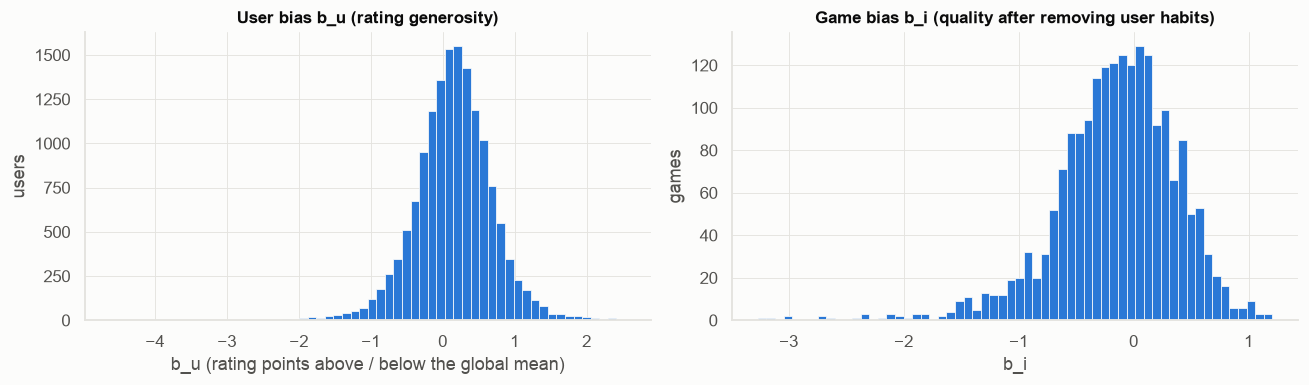

In [35]:
figures.biases(svd.bu, svd.bi)
facts({"global mean μ": frame.trainset.global_mean, "user bias, 5th percentile": np.percentile(svd.bu, 5), "user bias, 95th percentile": np.percentile(svd.bu, 95)},
      formats={"global mean μ": "rating", "user bias, 5th percentile": "signed rating", "user bias, 95th percentile": "signed rating"})
show(analysis.biases(svd, items).nlargest(8, "b_i"), "Highest game bias", formats=bias_formats)
show(analysis.biases(svd, items).nsmallest(8, "b_i"), "Lowest game bias", formats=bias_formats)

- **User generosity spans about 1.7 rating points** (5th–95th percentile: −0.72 to +0.99).
- **The highest game biases** (about +1.05 to +1.2) belong to recent heavy hobby games and legacy or second editions, rated by self-selected fans.
- **The lowest biases** (−2.4 to −3.3) belong to children's and roll-and-move classics (*Chutes and Ladders*, *Tic-Tac-Toe*, *Bingo*, *Candy Land*), rated by hobbyists who dislike them.

This is the mechanism behind section 4.2: rating models push the high-b<sub>i</sub> fan favourites to the top of almost everyone's list.

## 7. Conclusions

| Question | Answer |
|---|---|
| Best model for **predicting ratings** | **Tuned SVD** (300 factors, `reg_all` 0.1, 60 epochs): RMSE 1.171, MAE 0.861; in 5-fold CV 1.168 ± 0.002, better than item-KNN in every fold. Averaging it with item-KNN gives the best RMSE, **1.167** (+4.1% over `BaselineOnly`). |
| Does normalisation matter? | **Yes, decisively:** item-KNN on raw ratings is worse than the bias baseline (1.252 vs 1.217); any normalisation brings it to about 1.176. |
| Best model for **top-10 recommendations** | **EASE** (learned item-to-item weights): P@10 **0.145**, R@10 0.235, NDCG@10 0.241, hit rate **69%**. That is **+89% over "most popular"** and about 5× the best rating model. It wins on the long tail, for short and long histories, and for every definition of "liked". |
| Does lower RMSE mean better lists? | **No.** Every RMSE-optimised model loses to plain popularity on top-N. Ratings are missing not at random, so a useful list must predict *what users will play*, not only *how much they would like it*. |
| Does a random split tell the truth? | **Not fully.** On what users rated next, every model loses accuracy, popularity collapses, and the co-rating KNN's lead over SVD vanishes; only EASE stays clearly ahead. 55% of future ratings went to games outside the 2022 catalogue. |
| Beyond accuracy | The accurate lists are more mainstream than what users play; re-ranking against popularity buys a third more catalogue coverage at no cost in precision. |
| What did the models learn? | Without metadata, the SVD factors recover a hobbyist ↔ mass-market axis and a thematic ↔ abstract axis; item neighbourhoods group game families, designers and audiences; EASE's lists follow each user's taste in complexity. |

**How this compares.** On the relative measures, the rating models perform as in Surprise's own MovieLens-1M benchmark (SVD +4.0% over `BaselineOnly`, RMSE/std 0.78 there vs 0.77 here), and better than earlier BGG projects (e.g. SVD RMSE 1.28 on a similar 1,800-game core). The gain of the list models over popularity is larger than in the published BGG recommender study (Ion, Sacharidis & Werthner, SAC 2020: +20% precision).

**Limitations.**
- Modelling uses 15,000 sampled users and the 2,000 most-rated games of 2022 (the appendix shows the conclusions hold on four other frames); new users and new games are out of scope.
- The dataset has no rating dates: the "future" is a three-year window between two snapshots.
- Ranking metrics count only observed ratings as hits, so absolute precision is underestimated for every model.
- "Liked = rating ≥ 8" is a modelling choice (≥ 7 and ≥ 9 give the same ordering).
- BGG users are enthusiasts, not the general public.

**Next steps:** a hybrid with game metadata for games too new to have ratings; ranking-specific training for the rating models (e.g. BPR); a novelty-aware re-ranking step in production; periodic retraining evaluated on time-ordered data.

## Appendix: robustness

Do the conclusions depend on the particular sample? The main comparisons are repeated on other frames: two other random user samples, users with at least 50 ratings, and a larger catalogue of 4,000 games, with the same functions as the main analysis. Tuned parameters are reused; the precision comparison uses the users present in both test sets. Results are cached on disk.

In [36]:
robustness = pd.DataFrame({label: evaluation.headline(spec, tuned, cfg) for label, spec in [("main frame", cfg.frame), *cfg.robustness]})
show(robustness, "Main comparisons on five frames", default="rmse", formats={"ratings in frame": "count"})

,main frame,user sample seed 7,user sample seed 123,users with ≥ 50 ratings,"top 4,000 games"
ratings in frame,1271828.0000,1287959.0000,1298831.0000,2025739.0000,1398616.0000
RMSE BaselineOnly: random,1.2166,1.2079,1.2101,1.2024,1.2078
RMSE BaselineOnly: future,1.2655,1.2487,1.2449,1.2252,1.2504
RMSE Item-KNN: baseline (KNNBaseline): random,1.1750,1.1662,1.1689,1.1508,1.1699
RMSE Item-KNN: baseline (KNNBaseline): future,1.2779,1.2562,1.2512,1.2171,1.2619
RMSE SVD (tuned): random,1.1714,1.1627,1.1654,1.1483,1.1650
RMSE SVD (tuned): future,1.2471,1.2288,1.2243,1.1941,1.2324
P@10 Popularity: random,0.0898,0.0928,0.0922,0.1168,0.0876
P@10 Popularity: future,0.0395,0.0391,0.0385,0.0398,0.0371
P@10 SVD (tuned): random,0.0376,0.0352,0.0361,0.0489,0.0251


**The conclusions hold on every frame.** On all five frames the RMSE order is the same (SVD ≤ item-KNN < `BaselineOnly` on the random split, with item-KNN falling behind on the future), and EASE is the best list model on both test sets (P@10 0.17–0.22 random, 0.083–0.089 future), followed by the co-rating KNN, with popularity collapsing on the future.